# Fig 2 · Storage and search time

* **A** storage of every index, with the folds whole → Spindle-naive and Spindle-naive → Spindle.
* **B** whole-tile search time per query (search only): whole-matrix scan, Spindle-naive and Spindle, and the
  speed-ups whole → Spindle-naive and Spindle-naive → Spindle.
* **C** gene-set search time per query (search only): Spindle-naive (its scan without the query logs it computes)
  and Spindle, and the speed-up of Spindle over Spindle-naive.

Mean ± s.d. over seeds 0–4. Rows are shared by the three panels. Build time, the cell ladder, the dataset table and
the query-log times are appendix material (`experiments/figures/_backup_2026-11-01/`).

**Run first:** `R0_index_cache` → `R1_index_cost` (`results/index_cost/builds.csv`) and `R4_timing`
(`results/timing/whole_tile.csv`, `gene_set.csv`).
Writes `figures/fig2_cost/panels/{A,B,C,legend_A,legend_BC}.{pdf,png}` and `figures/fig2_cost/fig2_cost.{pdf,png}`.

In [1]:
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import gene_set_accuracy as gsa
import style as ps
import whole_tile as wt

FIG = "fig2_cost"
RES = ROOT / "results" / "index_cost"
ORDER = ps.DATASET_ORDER
TC = ps.TIER_COLORS
WHOLE, NAIVE, SPINDLE, SPINDLE_GS = TC["whole"], TC["naive"], TC["spindle"], TC["spindle_partial"]

b = pd.read_csv(RES / "builds.csv")
b["key"] = pd.Categorical(b["key"], ORDER, ordered=True)
b = b.sort_values(["key", "seed"])
_, t_whole = wt.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "whole_tile.csv"))
t_whole = t_whole.set_index("key")
_, _, t_gene = gsa.timing_tables(pd.read_csv(ROOT / "results" / "timing" / "gene_set.csv"))
t_gene = t_gene.set_index("key")
print(sorted(set(b.tag)))

# one row (mm): the three panels share the height and vertical margins, so the dataset rows line up
H, TOP, BOTTOM = 58.0, 5.5, 12.0
LEG_H = 11.0
ROW_OFF = 0.17  # the two storage rows of a dataset
STORAGE_XLIM = (0.7, 8000.0)  # MB
W_A, W_B, W_C = 64.0, 64.0, 52.0
LABEL_W = 20.0  # dataset labels of A


def box(fig, x, y, w, h):
    """Axes occupying the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H_ - y - h)


def rows(ax):
    n = len(ORDER)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_yticks(range(n))
    return n


def mean_sd(col):
    g = b.groupby("key", observed=True)[col]
    return g.mean().to_numpy(), g.std().to_numpy()


def marker(ax, x, y, tier, mk, filled=True, xerr=None, ms=3.2):
    k = TC[tier]
    ax.errorbar(x, y, xerr=xerr, fmt=mk, ms=ms, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                elinewidth=0.6, zorder=3)


def row_axis(ax):
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)

['method-v2']


## A · Storage (fold labels: whole → Spindle-naive, Spindle-naive → Spindle, of the means over seeds)

figures/fig2_cost/panels/A.pdf/.png: 64 x 58 mm, 0.0 / 0.3 MB


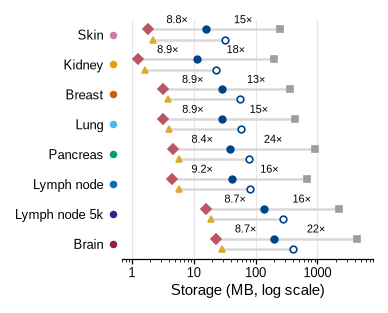

In [2]:
def fold_label(f):
    return f"{f:.0f}×" if f >= 10 else f"{f:.1f}×"


def panel_a(fig):
    ax = box(fig, LABEL_W, TOP, W_A - LABEL_W - 1.5, H - TOP - BOTTOM)
    n = rows(ax)
    y = np.arange(n)
    up, lo = y - ROW_OFF, y + ROW_OFF
    mb = {c: tuple(v / 1e6 for v in mean_sd(f"bytes_{c}"))
          for c in ("whole", "naive", "spindle", "naive_partial", "spindle_partial")}
    for yy, a, c in ((up, "whole", "spindle"), (lo, "naive_partial", "spindle_partial")):
        ax.hlines(yy, mb[c][0], mb[a][0], color=ps.LIGHT, lw=1.2, zorder=1)
    for c, yy, tier, mk, filled in (("whole", up, "whole", "s", True), ("naive", up, "naive", "o", True),
                                    ("spindle", up, "spindle", "D", True), ("naive_partial", lo, "naive", "o", False),
                                    ("spindle_partial", lo, "spindle_partial", "^", True)):
        marker(ax, mb[c][0], yy, tier, mk, filled, xerr=mb[c][1])
    for i in range(n):  # folds at the log midpoints, above the whole-tile row
        for a, c in (("naive", "whole"), ("spindle", "naive")):
            xm = math.sqrt(mb[a][0][i] * mb[c][0][i])
            ax.text(xm, up[i] - 0.13, fold_label(mb[c][0][i] / mb[a][0][i]), ha="center", va="bottom", fontsize=5.5)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(*STORAGE_XLIM)
    ax.set_xlabel("Storage (MB, log scale)")
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in ORDER])
    ax.tick_params(axis="y", length=0, pad=9)
    ax.spines["left"].set_visible(False)
    for i, k in enumerate(ORDER):  # the dataset's colour, as in every other figure
        ax.plot(-0.035, i, "o", ms=2.6, color=ps.DATASET_COLORS[k], clip_on=False, transform=ax.get_yaxis_transform())


fig = ps.panel(W_A, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Whole-tile search time per query (search only) and the speed-ups

figures/fig2_cost/panels/B.pdf/.png: 64 x 58 mm, 0.0 / 0.2 MB


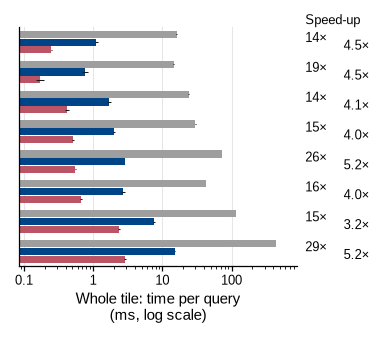

In [3]:
def time_axes(ax, xlabel):
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    rows(ax)
    row_axis(ax)
    ax.set_xlabel(xlabel)


def panel_b(fig):
    W, _ = ps.size_mm(fig)
    right = 15.0
    ax = box(fig, 2.0, TOP, W - 2.0 - right, H - TOP - BOTTOM)
    t = t_whole
    bh = 0.26
    for i, k in enumerate(ORDER):
        r = t.loc[k]
        for off, col, c in ((-bh, "whole_ms", WHOLE), (0, "naive_ms", NAIVE), (bh, "spindle_ms", SPINDLE)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
    time_axes(ax, "Whole tile: time per query\n(ms, log scale)")
    ax.set_xlim(t.spindle_ms.min() / 2, t.whole_ms.max() * 2)
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    for i, k in enumerate(ORDER):  # whole-matrix scan / Spindle-naive (left), Spindle-naive / Spindle (right)
        r = t.loc[k]
        ax.text(1.03, i - bh / 2, f"{r.speedup_naive_vs_whole:.0f}×", transform=tr, fontsize=ps.TICK_PT, va="center")
        ax.text(1.03 + 6.5 / (W - 2.0 - right), i + bh / 2, f"{r.speedup_spindle_vs_naive:.1f}×", transform=tr,
                fontsize=ps.TICK_PT, va="center")
    ax.text(1.03, 1.0, "Speed-up", transform=ax.transAxes, ha="left", va="bottom", fontsize=ps.TICK_PT)


fig = ps.panel(W_B, H); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · Gene-set search time per query (search only) and the speed-up

figures/fig2_cost/panels/C.pdf/.png: 52 x 58 mm, 0.0 / 0.1 MB


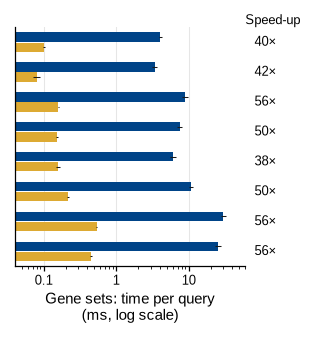

In [4]:
def panel_c(fig):
    W, _ = ps.size_mm(fig)
    right = 11.0
    ax = box(fig, 2.0, TOP, W - 2.0 - right, H - TOP - BOTTOM)
    t = t_gene
    bh = 0.34
    for i, k in enumerate(ORDER):
        r = t.loc[k]
        for off, col, c in ((-bh / 2, "naive_partial_search_ms", NAIVE), (bh / 2, "spindle_partial_ms", SPINDLE_GS)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
    time_axes(ax, "Gene sets: time per query\n(ms, log scale)")
    ax.set_xlim(t.spindle_partial_ms.min() / 2, t.naive_partial_search_ms.max() * 2)
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    for i, k in enumerate(ORDER):
        ax.text(1.04, i, f"{t.loc[k].speedup_spindle_partial:.0f}×", transform=tr, ha="left", va="center",
                fontsize=ps.TICK_PT)
    ax.text(1.0, 1.0, "Speed-up", transform=ax.transAxes, ha="left", va="bottom", fontsize=ps.TICK_PT)


fig = ps.panel(W_C, H); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Legends and full figure

figures/fig2_cost/panels/legend_A.pdf/.png: 64 x 11 mm, 0.0 / 0.1 MB
figures/fig2_cost/panels/legend_BC.pdf/.png: 116 x 11 mm, 0.0 / 0.1 MB
figures/fig2_cost/fig2_cost.pdf/.png: 180 x 69 mm, 0.0 / 0.8 MB


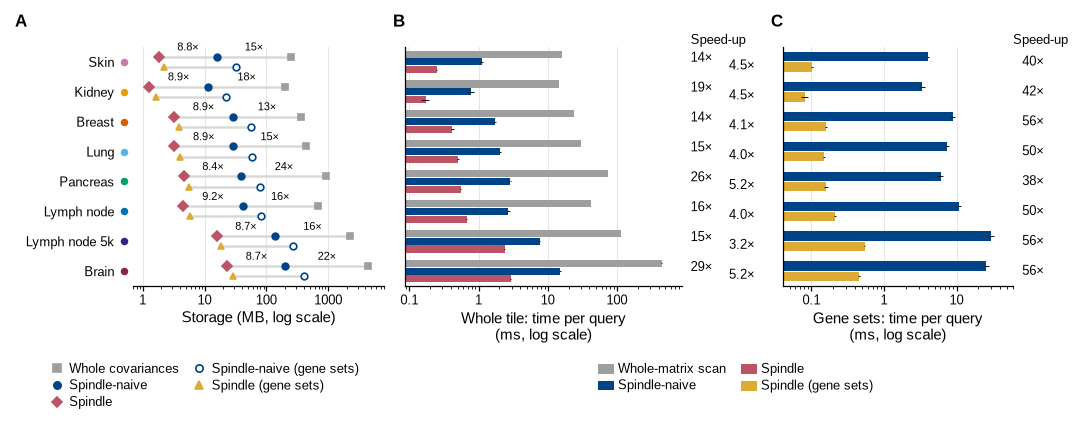

<Figure size 377.953x64.9606 with 0 Axes>

<Figure size 685.039x64.9606 with 0 Axes>

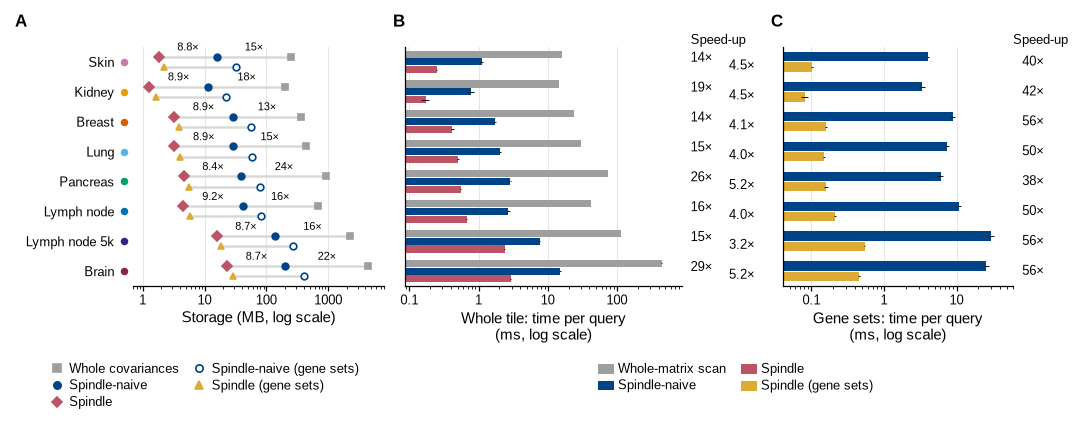

In [5]:
def legend_a(fig):
    def h(tier, mk, label, filled=True):
        k = TC[tier]
        return Line2D([], [], ls="", marker=mk, ms=3.5, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                      label=label)

    handles = [h("whole", "s", "Whole covariances"), h("naive", "o", "Spindle-naive"), h("spindle", "D", "Spindle"),
               h("naive", "o", "Spindle-naive (gene sets)", filled=False),
               h("spindle_partial", "^", "Spindle (gene sets)")]
    fig.legend(handles=handles, ncol=2, loc="upper center", columnspacing=1.0)


def legend_bc(fig):
    handles = [Patch(color=WHOLE, label="Whole-matrix scan"), Patch(color=NAIVE, label="Spindle-naive"),
               Patch(color=SPINDLE, label="Spindle"), Patch(color=SPINDLE_GS, label="Spindle (gene sets)")]
    fig.legend(handles=handles, ncol=2, loc="upper center", columnspacing=1.2)


fig = ps.panel(W_A, LEG_H); legend_a(fig); ps.save_panel(fig, FIG, "legend_A")
fig = ps.panel(W_B + W_C, LEG_H); legend_bc(fig); ps.save_panel(fig, FIG, "legend_BC")

page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
legend_a(ps.place(page, None, 0, H + 1.0, W_A, LEG_H - 1.0))
legend_bc(ps.place(page, None, W_A, H + 1.0, W_B + W_C, LEG_H - 1.0))
ps.save_figure(page, FIG)
page